In [2]:
%pip install -U ucimlrepo imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


Original class distribution:
Revenue
0    10422
1     1908
Name: count, dtype: int64

Train: 7398
Validation: 2466
Test (reserved): 2466
Trained: Baseline
Trained: Random Oversampling
Trained: Random Undersampling
Trained: SMOTENC

Fixed Threshold = 0.5


,Method,Threshold,Accuracy,Precision,Recall,F1,AP,ROC-AUC
0,Baseline,0.5,0.886,0.746,0.402,0.522,0.660,0.890
1,Random Oversampling,0.5,0.835,0.480,0.780,0.594,0.671,0.901
2,Random Undersampling,0.5,0.833,0.475,0.790,0.593,0.666,0.897
3,SMOTENC,0.5,0.842,0.493,0.719,0.585,0.633,0.868



Optimized Threshold Results:


,Method,Threshold,Accuracy,Precision,Recall,F1
149,Random Oversampling,0.63,0.889,0.627,0.693,0.658
243,Random Undersampling,0.66,0.889,0.634,0.664,0.649
19,Baseline,0.24,0.883,0.613,0.654,0.633
325,SMOTENC,0.57,0.863,0.544,0.680,0.604


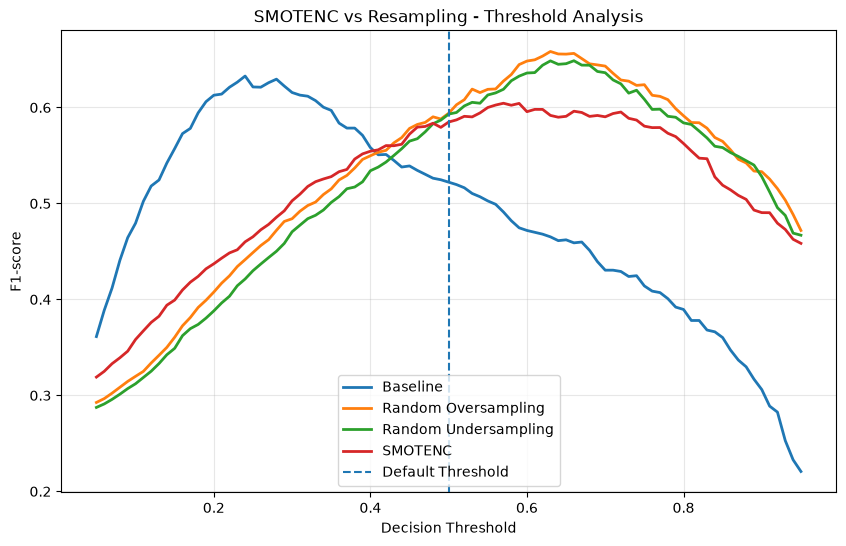

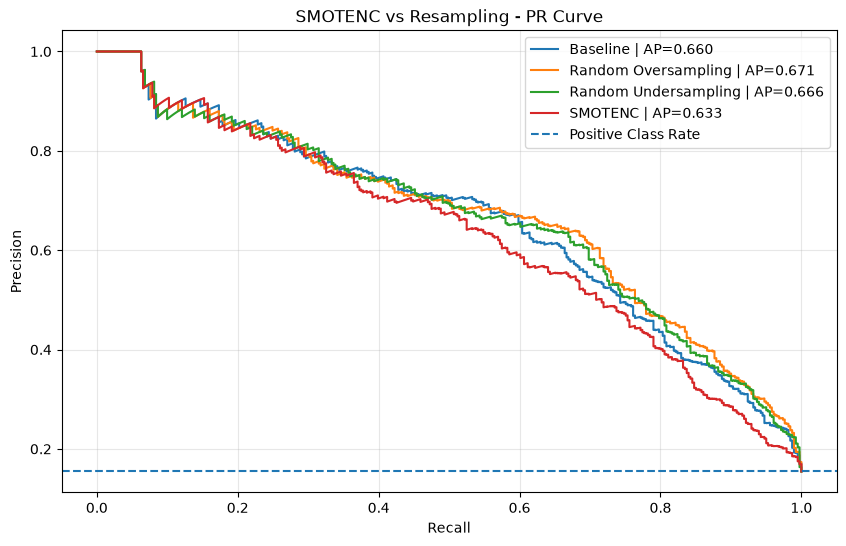

In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    average_precision_score, roc_auc_score
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTENC
from imblearn.under_sampling import RandomUnderSampler


# ==========================================
# 1. Load Dataset
# ==========================================

dataset = fetch_ucirepo(id=468)

X = dataset.data.features.copy()
y = dataset.data.targets["Revenue"].astype(int)

print("Original class distribution:")
print(y.value_counts().sort_index())


# ==========================================
# 2. Split: Train / Validation / Test
# ==========================================

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.25,
    stratify=y_temp,
    random_state=42
)

print("\nTrain:", len(X_train))
print("Validation:", len(X_val))
print("Test (reserved):", len(X_test))


# ==========================================
# 3. Identify Feature Types
# ==========================================

categorical_cols = [
    "Month", "OperatingSystems",
    "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]

numeric_cols = [
    col for col in X.columns
    if col not in categorical_cols
]


# ==========================================
# 4. Build Training Pipeline
# ==========================================

def build_model(sampler):

    # Scale numeric features while preserving
    # categorical features and column names.
    pre_sampler = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numeric_cols),
            ("cat", "passthrough", categorical_cols)
        ],
        verbose_feature_names_out=False
    ).set_output(transform="pandas")

    # Encode categorical features after sampling.
    post_sampler = ColumnTransformer(
        transformers=[
            ("num", "passthrough", numeric_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore"),
             categorical_cols)
        ]
    )

    return Pipeline([
        ("pre_sampler", pre_sampler),
        ("sampler", sampler),
        ("post_sampler", post_sampler),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ])


# ==========================================
# 5. Define Four Models
# ==========================================

models_smote = {
    "Baseline": build_model("passthrough"),

    "Random Oversampling": build_model(
        RandomOverSampler(random_state=42)
    ),

    "Random Undersampling": build_model(
        RandomUnderSampler(random_state=42)
    ),

    "SMOTENC": build_model(
        SMOTENC(
            categorical_features=categorical_cols,
            k_neighbors=5,
            random_state=42
        )
    )
}


# ==========================================
# 6. Train All Models
# ==========================================

for name, model in models_smote.items():
    model.fit(X_train, y_train)
    print("Trained:", name)


# ==========================================
# 7. Evaluation Function
# ==========================================

def calculate_metrics(y_true, probs, threshold):

    predictions = (probs >= threshold).astype(int)

    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        )
    }


# ==========================================
# 8. Validation Probabilities
# ==========================================

val_probs = {
    name: model.predict_proba(X_val)[:, 1]
    for name, model in models_smote.items()
}


# ==========================================
# 9. Fixed Threshold Comparison
# ==========================================

fixed_rows = []

for name, probs in val_probs.items():

    scores = calculate_metrics(
        y_val, probs, threshold=0.5
    )

    fixed_rows.append({
        "Method": name,
        "Threshold": 0.5,
        **scores,
        "AP": average_precision_score(y_val, probs),
        "ROC-AUC": roc_auc_score(y_val, probs)
    })

fixed_results = pd.DataFrame(fixed_rows)

print("\nFixed Threshold = 0.5")
display(fixed_results.round(3))


# ==========================================
# 10. Optimize Threshold on Validation
# ==========================================

thresholds = np.round(
    np.arange(0.05, 0.951, 0.01), 2
)

all_rows = []

for name, probs in val_probs.items():

    for threshold in thresholds:

        scores = calculate_metrics(
            y_val, probs, threshold
        )

        all_rows.append({
            "Method": name,
            "Threshold": threshold,
            **scores
        })

comparison_df = pd.DataFrame(all_rows)

best_indices = comparison_df.groupby(
    "Method"
)["F1"].idxmax()

best_results = comparison_df.loc[
    best_indices
].sort_values(
    "F1", ascending=False
)

print("\nOptimized Threshold Results:")
display(best_results.round(3))


# ==========================================
# 11. Plot F1 vs Threshold
# ==========================================

plt.figure(figsize=(10, 6))

for name in models_smote.keys():

    data = comparison_df[
        comparison_df["Method"] == name
    ]

    plt.plot(
        data["Threshold"],
        data["F1"],
        label=name,
        linewidth=2
    )

plt.axvline(
    x=0.5,
    linestyle="--",
    label="Default Threshold"
)

plt.xlabel("Decision Threshold")
plt.ylabel("F1-score")
plt.title("SMOTENC vs Resampling - Threshold Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ==========================================
# 12. Precision-Recall Curves
# ==========================================

from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(10, 6))

for name, probs in val_probs.items():

    precision, recall, _ = precision_recall_curve(
        y_val, probs
    )

    ap = average_precision_score(y_val, probs)

    plt.plot(
        recall, precision,
        label=f"{name} | AP={ap:.3f}"
    )

plt.axhline(
    y=y_val.mean(),
    linestyle="--",
    label="Positive Class Rate"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("SMOTENC vs Resampling - PR Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
